In [3]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [4]:
class bmi_state(TypedDict):
    weight_kg : float
    height_m : float
    bmi : float
    category : str
    

In [5]:
def bmi_calculator(state : bmi_state) -> bmi_state:

    weight = state["weight_kg"]
    height = state["height_m"]

    bmi = weight/(height**2)

    state["bmi"] = round(bmi, 2)

    return state

In [6]:
def label_bmi(state : bmi_state) -> bmi_state:
    bmi = state["bmi"]
    if bmi <= 25:
        state["category"] = "underfit"
    elif bmi >= 40:
        state["category"] = "overfit"
    else:
        state["category"] = "normal"
    return state

In [7]:
#define graph
graph = StateGraph(bmi_state)

#add node
graph.add_node("bmi_state", bmi_calculator)
graph.add_node("label_bmi", label_bmi)

#add edges
graph.add_edge(START, "bmi_state")
graph.add_edge("bmi_state", "label_bmi")
graph.add_edge("label_bmi", END)

#complie
workflow = graph.compile()

In [10]:
initial_state = {"weight_kg" : 90, "height_m" : 1.43}
final_state = workflow.invoke(initial_state)
print(final_state)

{'weight_kg': 90, 'height_m': 1.43, 'bmi': 44.01, 'category': 'overfit'}


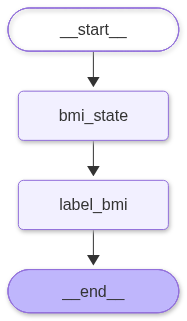

In [11]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())